In [53]:
import numpy as np
import cv2
from starter_pack.code import utils, align_images
from pyramids import build_gaussian_pyramid, build_laplacian_pyramid, reconstruct_laplacian_pyramid, multiresolution_blend

In [2]:
apple = utils.load_image("starter_pack\images\part2_frequencies\\apple.jpg")
orange = utils.load_image("starter_pack\images\part2_frequencies\orange.jpg")

<>:1: SyntaxWarning: invalid escape sequence '\i'
<>:2: SyntaxWarning: invalid escape sequence '\i'
<>:1: SyntaxWarning: invalid escape sequence '\i'
<>:2: SyntaxWarning: invalid escape sequence '\i'
C:\Users\bodyy\AppData\Local\Temp\ipykernel_8256\2258953020.py:1: SyntaxWarning: invalid escape sequence '\i'
  apple = utils.load_image("starter_pack\images\part2_frequencies\\apple.jpg")
C:\Users\bodyy\AppData\Local\Temp\ipykernel_8256\2258953020.py:2: SyntaxWarning: invalid escape sequence '\i'
  orange = utils.load_image("starter_pack\images\part2_frequencies\orange.jpg")


In [3]:
min_h = min(apple.shape[0], orange.shape[0])
min_w = min(apple.shape[1], orange.shape[1])

apple = apple[:min_h, :min_w]
orange = orange[:min_h, :min_w]

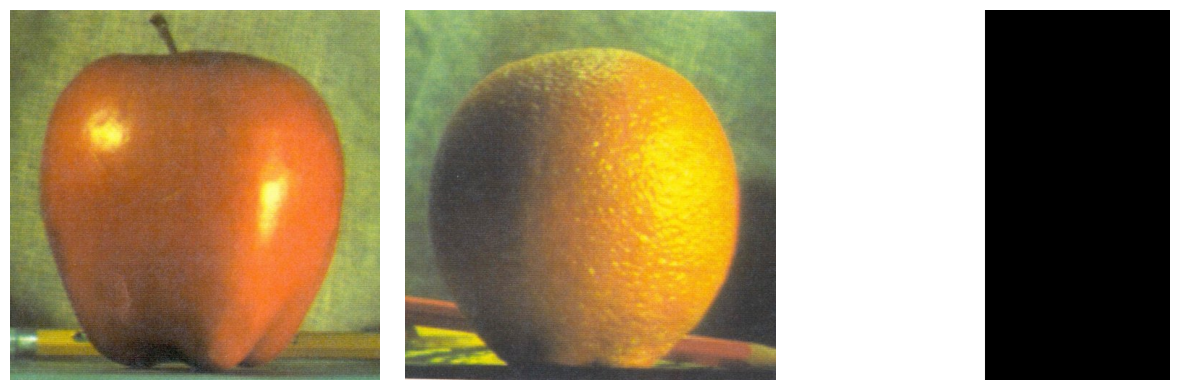

In [4]:
mask = np.zeros((min_h, min_w), dtype=np.float64)
mask[:, :min_w // 2] = 1.0
utils.show(apple, orange, mask)

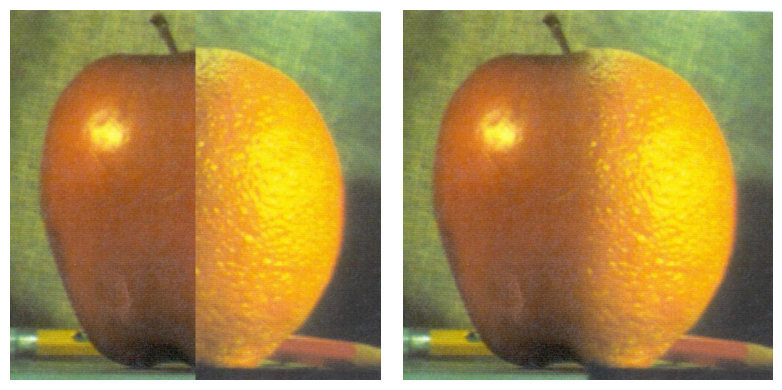

In [ ]:
blended_result=multiresolution_blend(apple, orange, mask)
naive_blend = mask[:, :, None] * apple + (1.0 - mask[:, :, None]) * orange
utils.show(naive_blend,blended_result)

In [ ]:
glazed = utils.load_image("glazed.jpg")
donut = utils.load_image("donut.jpg")
%matplotlib tk
pts_glazed = align_images.pick_points(glazed)
pts_donut = align_images.pick_points(donut)
%matplotlib inline

donut = align_images.align_images(glazed, donut, pts_glazed, pts_donut)

print("donut shape:", donut.shape)
print("glazed shape:", glazed.shape)

donut shape: (740, 740, 3)
glazed shape: (740, 740, 3)


In [60]:
h, w = glazed.shape[:2]
mask_2 = np.zeros((h, w), dtype=np.float64)
mask_2[:, :w // 2] = 1.0
cv2.ellipse(
    mask_2,
    center=(w // 2, h // 2),
    axes=(int(w * 0.18), int(h * 0.38)),
    angle=0,
    startAngle=0,
    endAngle=360,
    color=1.0,
    thickness=-1
)

array([[1., 1., 1., ..., 0., 0., 0.],
       [1., 1., 1., ..., 0., 0., 0.],
       [1., 1., 1., ..., 0., 0., 0.],
       ...,
       [1., 1., 1., ..., 0., 0., 0.],
       [1., 1., 1., ..., 0., 0., 0.],
       [1., 1., 1., ..., 0., 0., 0.]], shape=(740, 740))

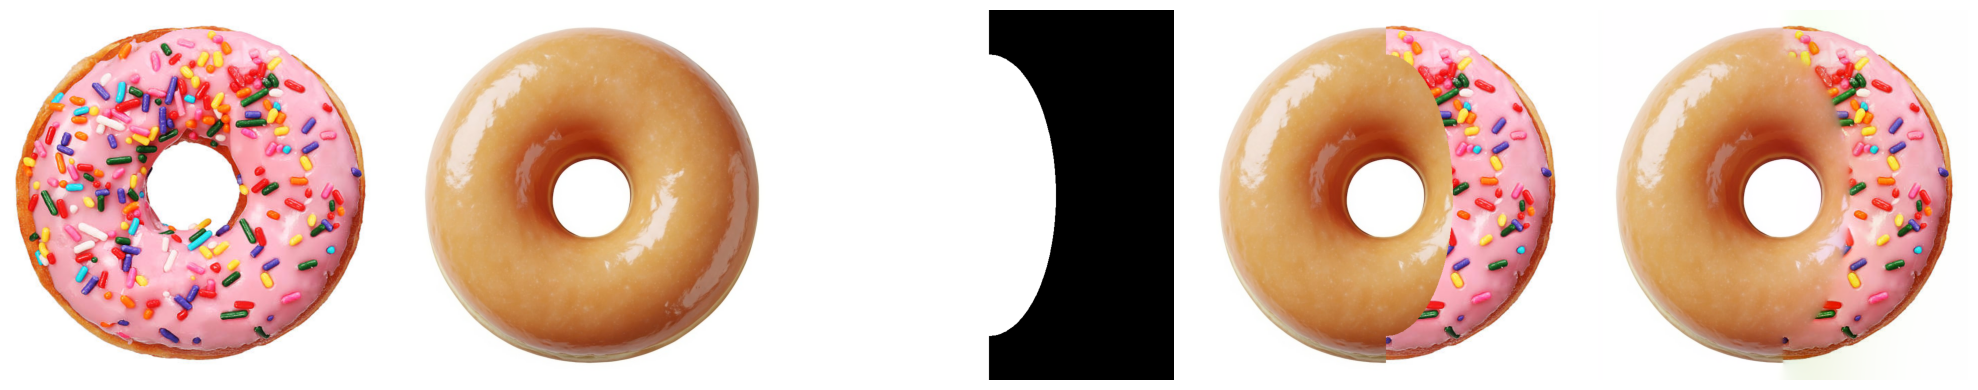

In [63]:
blended_2 = multiresolution_blend(glazed, donut, mask_2, levels=7)
naive_blend = mask_2[:, :, None] * glazed + (1.0 - mask_2[:, :, None]) * donut
utils.show(donut, glazed, mask_2, naive_blend,blended_2)

In [ ]:
euro = utils.load_image("euro.png")
gneh = utils.load_image("gneh.jpg")
%matplotlib tk
pts_euro = align_images.pick_points(euro)
pts_gneh = align_images.pick_points(gneh)
%matplotlib inline

gneh_aligned = align_images.align_images(euro, gneh, pts_euro, pts_gneh)

print("euro shape:", gneh_aligned.shape)
print("gneh shape:", euro.shape)



euro shape: (300, 301, 3)
gneh shape: (300, 301, 3)


In [77]:
h, w = euro.shape[:2]
mask_3 = np.zeros((h, w), dtype=np.float64)
mask_3[:, :w // 2] = 1.0
cv2.ellipse(
    mask_3,
    center=(w // 2, h // 2),
    axes=(int(w * 0.38), int(h * 0.28)),
    angle=0,
    startAngle=0,
    endAngle=360,
    color=1.0,
    thickness=-1
)

array([[1., 1., 1., ..., 0., 0., 0.],
       [1., 1., 1., ..., 0., 0., 0.],
       [1., 1., 1., ..., 0., 0., 0.],
       ...,
       [1., 1., 1., ..., 0., 0., 0.],
       [1., 1., 1., ..., 0., 0., 0.],
       [1., 1., 1., ..., 0., 0., 0.]], shape=(300, 301))

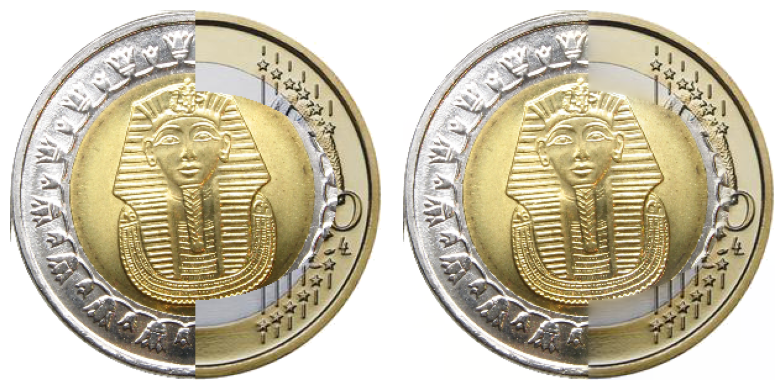

In [78]:
blended = multiresolution_blend(gneh_aligned, euro, mask_3, levels=5)
naive_blend = mask_3[:, :, None] * gneh_aligned + (1.0 - mask_3[:, :, None]) * euro
utils.show(naive_blend,blended)

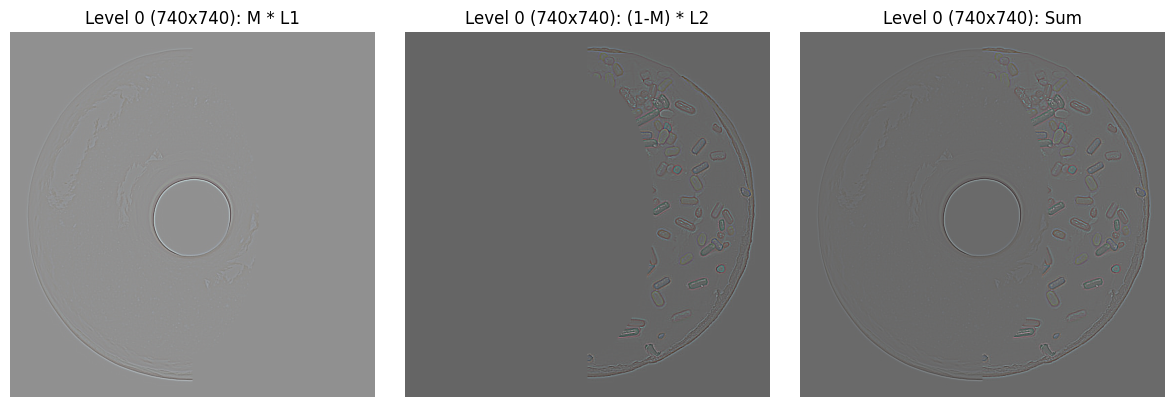

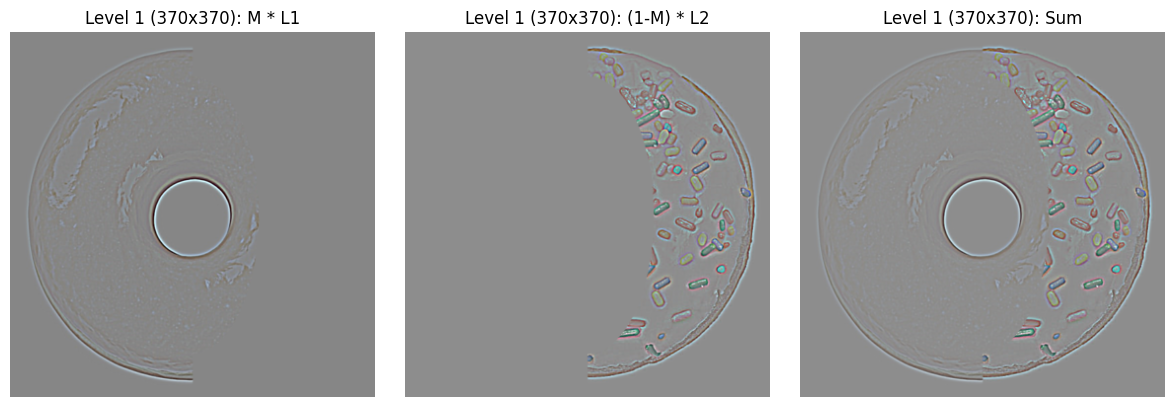

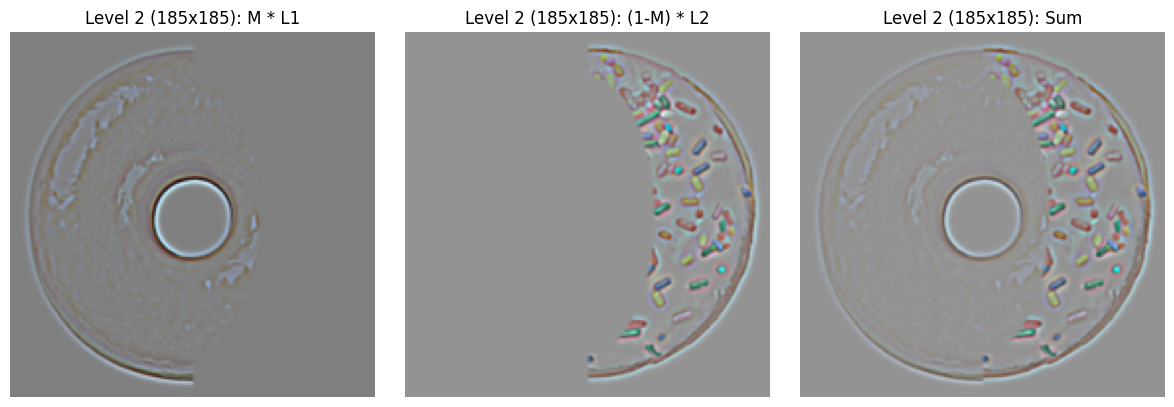

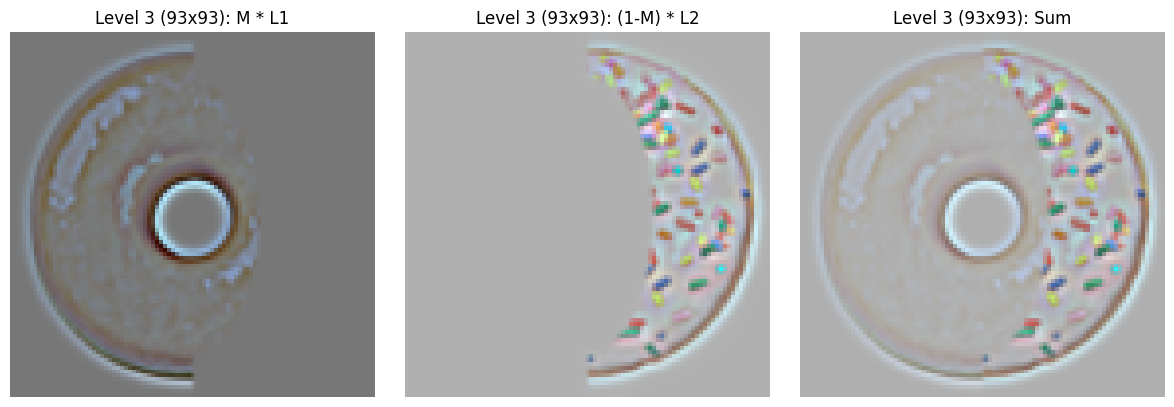

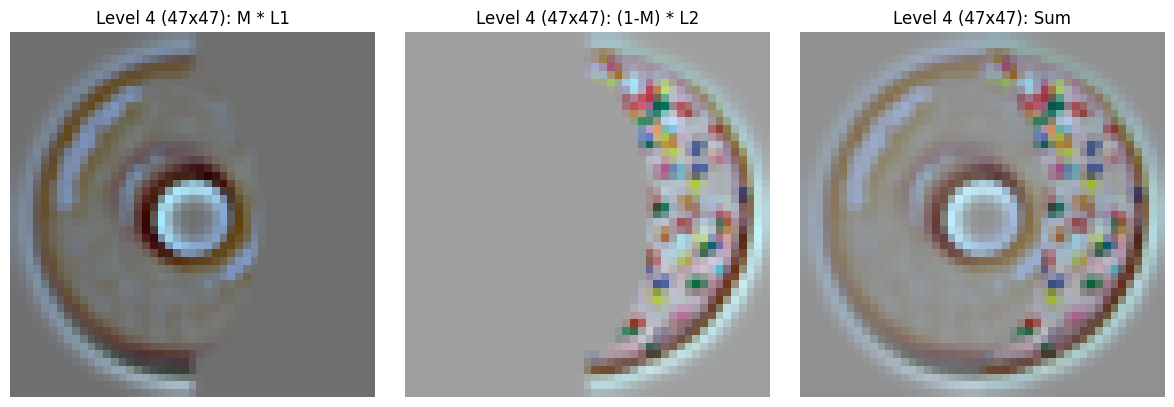

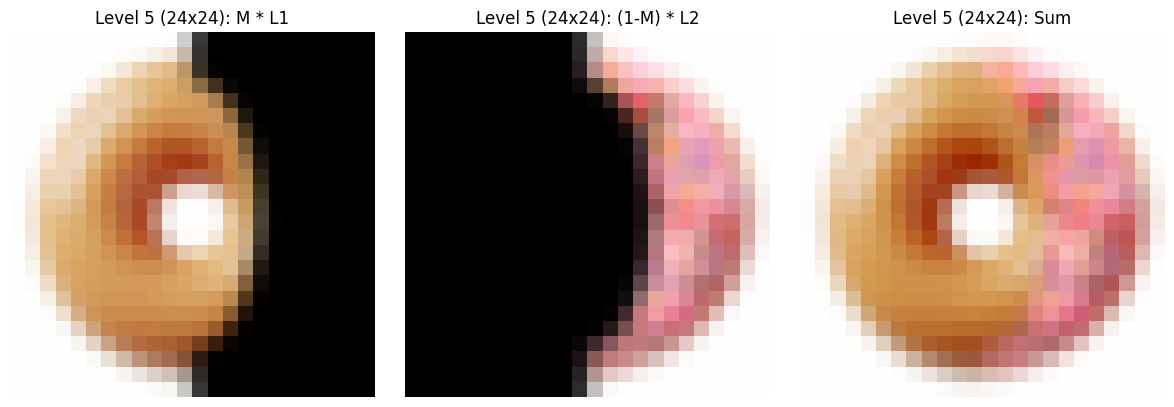

In [85]:
img_1 = glazed
img_2 = donut
fav_mask = mask_2
levels = 5

L1 = build_laplacian_pyramid(build_gaussian_pyramid(img_1, levels=levels))
L2 = build_laplacian_pyramid(build_gaussian_pyramid(img_2, levels=levels))
GM = build_gaussian_pyramid(fav_mask.astype(np.float64), levels=levels)

norm = lambda x: (x - x.min()) / (x.max() - x.min() + 1e-8)

for k in range(len(L1)):
    m_k = GM[k][:, :, None] if img_1.ndim == 3 else GM[k]
    ml1 = m_k * L1[k]
    ml2 = (1.0 - m_k) * L2[k]
    l_sum = ml1 + ml2
    h_k, w_k = L1[k].shape[:2]

    utils.show(
        norm(ml1),
        norm(ml2),
        norm(l_sum),
        titles=[
            f"Level {k} ({h_k}x{w_k}): M * L1",
            f"Level {k} ({h_k}x{w_k}): (1-M) * L2",
            f"Level {k} ({h_k}x{w_k}): Sum"
        ]
    )